<a href="https://colab.research.google.com/github/NoahJuganar/NoahJuganar-DataScience-GenAI-Submissions/blob/main/Week_3/Seminar_3_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## 1. Objective and dataset

This notebook performs exploratory data analysis (EDA) of the 891-row Titanic passenger dataset, following the seminar workflow: inspect variables, compare them, check outliers, examine missingness and engineer useful features.

**Reproducing in Colab:** Open this notebook using the badge above. Run all cells and upload the original `titanic.csv` from my.wbs if Colab requests it. Colab uploads are temporary. The source dataset is not stored in this repository.


In [ ]:
import pandas as pd
from pathlib import Path

# Colab runs in a temporary environment. Upload titanic.csv if it is not present.
csv_path = Path('/content/titanic.csv')
if not csv_path.exists():
    from google.colab import files
    print("Please upload the seminar dataset: titanic.csv")
    files.upload()

df = pd.read_csv(csv_path)
df.head()


In [12]:
df.shape

(891, 12)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [14]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


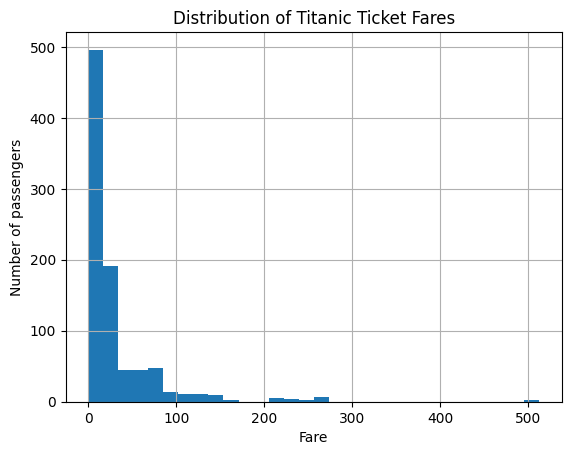

In [15]:
import matplotlib.pyplot as plt

df['Fare'].hist(bins=30)

plt.xlabel('Fare')
plt.ylabel('Number of passengers')
plt.title('Distribution of Titanic Ticket Fares')
plt.show()

In [16]:
df.groupby('Pclass')['Survived'].mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


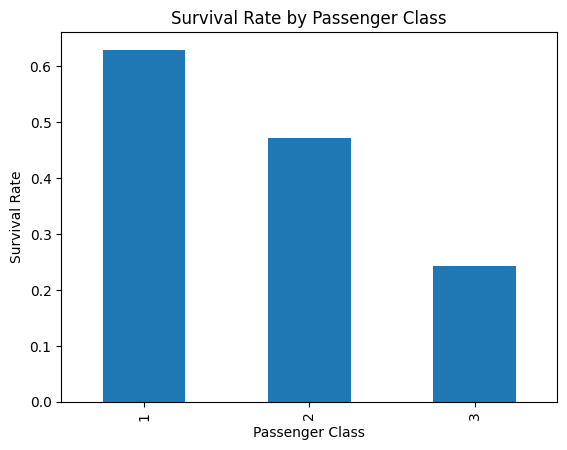

In [17]:
df.groupby('Pclass')['Survived'].mean().plot(kind='bar')

plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Passenger Class')
plt.show()

## 2. Univariate analysis
We examine individual variables to understand distributions, typical values, frequencies and potential issues. `Pclass` and `Survived` are coded numerically but represent categories; `PassengerId` is an identifier, not a quantity of interest.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Numerical variables: Age, SibSp and Parch
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'].dropna(), bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of passenger age')
axes[0].set_xlabel('Age (years)')

sns.countplot(data=df, x='SibSp', hue='SibSp', ax=axes[1], palette='Blues_d', legend=False)
axes[1].set_title('Recorded siblings / spouses')
axes[1].set_xlabel('SibSp')

sns.countplot(data=df, x='Parch', hue='Parch', ax=axes[2], palette='Greens_d', legend=False)
axes[2].set_title('Recorded parents / children')
axes[2].set_xlabel('Parch')

plt.tight_layout()
plt.show()

display(df[['Age', 'Fare', 'SibSp', 'Parch']].describe())


### Interpretation: numerical variables
- **Age:** The recorded ages cluster mainly among young and middle-aged adults; 177 ages are missing, so this chart excludes them.
- **SibSp and Parch:** The distributions are concentrated at zero or small values, with relatively few passengers reporting large family groups. These columns alone do not establish whether someone travelled entirely alone.
- **Fare:** The earlier histogram is strongly right-skewed: median fare is 14.45 compared with a mean of 32.20. Very high fares warrant investigation, not automatic deletion.


In [ ]:
# Frequencies for the main categorical variables
fig, axes = plt.subplots(1, 4, figsize=(19, 4))

sns.countplot(data=df, x='Survived', hue='Survived', ax=axes[0], palette='Set2', legend=False)
axes[0].set_xticks([0, 1], ['No (0)', 'Yes (1)'])
axes[0].set_title('Survival')

sns.countplot(data=df, x='Sex', hue='Sex', ax=axes[1], palette='pastel', legend=False)
axes[1].set_title('Sex')

sns.countplot(data=df, x='Pclass', hue='Pclass', ax=axes[2], palette='Blues', legend=False)
axes[2].set_title('Passenger class')

sns.countplot(data=df, x='Embarked', hue='Embarked', ax=axes[3], palette='Set3', legend=False)
axes[3].set_title('Embarkation port')

plt.tight_layout()
plt.show()

for col in ['Survived', 'Sex', 'Pclass', 'Embarked']:
    print(f"\nFrequency table: {col}")
    display(df[col].value_counts(dropna=False).sort_index())


### Interpretation: categorical variables
- **Survival:** 342 of 891 passengers survived (38.4%); 549 (61.6%) did not.
- **Sex:** The sample contains 577 males and 314 females.
- **Class:** Most records are third-class passengers (491 of 891).
- **Embarkation:** Most recorded boardings were at Southampton (S). Two embarkation values are missing.


## 3. Bivariate analysis
We examine how survival varies between groups. These are **descriptive associations**, not demonstrations of causation; passenger class, sex and age may be related to one another.


In [ ]:
# Survival rate by sex, and by sex within each class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Sex', y='Survived', hue='Sex', ax=axes[0],
            errorbar=None, palette='pastel', legend=False)
axes[0].set_title('Survival rate by sex')
axes[0].set_ylabel('Survival rate (proportion)')
axes[0].set_ylim(0, 1)

sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', ax=axes[1],
            errorbar=None, palette='muted')
axes[1].set_title('Survival rate by passenger class and sex')
axes[1].set_ylabel('Survival rate (proportion)')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

# Include denominators so differences in small groups can be judged.
pivot = df.groupby(['Pclass', 'Sex'])['Survived'].agg(Passengers='size', SurvivalRate='mean')
pivot['SurvivalRate'] = (100 * pivot['SurvivalRate']).round(2)
display(pivot.rename(columns={'SurvivalRate': 'Survival rate (%)'}))


### Interpretation: survival, sex and class
- Females survived at **74.2%** (314 passengers) versus **18.9%** for males (577 passengers).
- Survival varied by class *within* each sex: first-class females **96.8%** (94 passengers) versus third-class females **50.0%** (144); first-class males **36.9%** (122) versus third-class males **13.5%** (347).
- These differences suggest class and sex are both informative, but observational comparisons alone cannot establish the causal mechanisms.


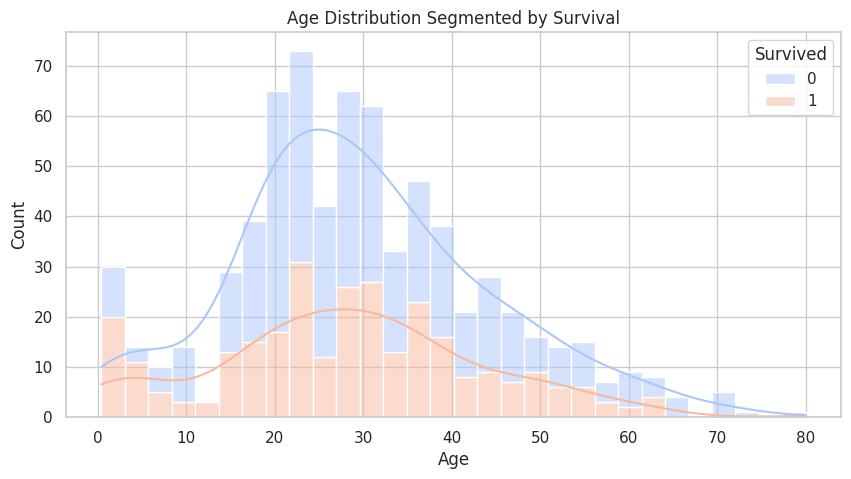

In [29]:
# 3. Survival patterns by Age
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Age', hue='Survived', kde=True, multiple='stack', bins=30, palette='coolwarm')
plt.title('Age Distribution Segmented by Survival')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### Interpretation: age and survival
The stacked age histogram shows the number of survivors and non-survivors at different ages, **not the probability of surviving at each age**. To compare survival fairly across unequal age-group sizes, calculate survival **rates** with passenger counts, excluding the 177 records with missing age.


In [ ]:
# Compare rates, rather than raw stacked histogram counts, using known ages only.
known_age = df.dropna(subset=['Age']).copy()
age_bins = [-np.inf, 5, 12, 17, 35, 60, np.inf]
age_labels = ['0-5', '6-12', '13-17', '18-35', '36-60', '61+']
known_age['AgeGroup'] = pd.cut(known_age['Age'], bins=age_bins, labels=age_labels)

age_summary = known_age.groupby('AgeGroup', observed=False)['Survived'].agg(
    Passengers='size', SurvivalRate='mean')
age_summary['SurvivalRate'] = (100 * age_summary['SurvivalRate']).round(1)
display(age_summary.rename(columns={'SurvivalRate': 'Survival rate (%)'}))

ax = age_summary['SurvivalRate'].plot(kind='bar', ylim=(0, 100), title='Survival rate by recorded age group')
ax.set_xlabel('Age group (years)')
ax.set_ylabel('Survival rate (%)')
plt.show()


The **0–5** age group had **44** passengers with recorded ages, of whom **31 survived (70.5%)**. The **61+** group had only **22** recorded passengers. Different group sizes and missing ages limit the conclusions.


In [ ]:
# Fares differ substantially across passenger classes.
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Pclass', y='Fare', hue='Survived', palette='Set2')
plt.yscale('symlog')  # Keeps zero fares visible while compressing very large values
plt.title('Fare by class and survival (symmetric-log scale)')
plt.xlabel('Passenger class')
plt.ylabel('Fare (dataset units; symmetric-log scale)')
plt.show()

fare_table = df.groupby(['Pclass', 'Survived'])['Fare'].agg(['size', 'median'])
display(fare_table)


### Interpretation: fare, class and survival
The observed median fare was higher among survivors within each ticket class (first class: 77.96 versus 44.75; second: 21.00 versus 13.00; third: 8.52 versus 8.05). The fare distribution is skewed, so medians are informative. These comparisons **do not establish** that paying more or occupying a particular cabin caused survival; fare is also related to class, ticket sharing and other factors.


In [ ]:
# Embarkation rates and group sizes; NaN is shown separately.
port_rates = df.groupby('Embarked', dropna=False).agg(
    Passengers=('Survived', 'size'),
    SurvivalRate=('Survived', 'mean'),
    MedianFare=('Fare', 'median'))
port_rates['SurvivalRate'] = (port_rates['SurvivalRate'] * 100).round(1)
display(port_rates.rename(columns={'SurvivalRate': 'Survival rate (%)'}))


**Embarkation comparison:** Recorded survival was approximately 55.4% for Cherbourg (168 people), 39.0% for Queenstown (77) and 33.7% for Southampton (644). Two embarkation ports are missing. These differences may reflect who boarded at each port, not a causal effect of the port.


## 4. Outliers and extreme values
Boxplots and the **1.5 × interquartile range (IQR)** rule flag unusually distant values. A statistical outlier is not automatically an error.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y='Fare', ax=axes[0], color='lightcoral')
axes[0].set_title('Fare: potential outliers')
sns.boxplot(data=df, y='Age', ax=axes[1], color='lightblue')
axes[1].set_title('Age: potential outliers')
plt.tight_layout()
plt.show()

for col in ['Fare', 'Age']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    unusual = df[col].notna() & ((df[col] < lower) | (df[col] > upper))
    print(f"{col}: IQR bounds [{lower:.2f}, {upper:.2f}], flagged records: {unusual.sum()}")

print("Zero fares:", (df['Fare'] == 0).sum())
print("Negative fares:", (df['Fare'] < 0).sum())
print("Nonpositive ages:", (df['Age'].dropna() <= 0).sum())
print("Ages above 100:", (df['Age'] > 100).sum())
print("Duplicate passenger identifiers:", df['PassengerId'].duplicated().sum())


### Interpretation: potential outliers and data quality
- **Fare:** 116 of 891 fares (13.0%) are above the IQR upper fence of **65.63**. High fares may be genuine, but the dataset alone does not prove the reason for each one. Keep them unless additional evidence identifies an error.
- **Age:** 11 ages exceed the IQR upper fence of **64.81**; the oldest recorded age is 80, which is plausible.
- **Zero fares:** 15 records show zero. Possible explanations include special ticket arrangements or data-recording issues, but these explanations are **not verified**. Flag them for investigation rather than changing them.
- **Identifiers:** No duplicated PassengerId values were found.


## 5. Missing values and cautious handling
We retain the original `df` and make a separate `df_clean` for demonstration. Imputation fills gaps for some purposes; it does **not** recover the true missing observations.


In [32]:
# Create missing values summary
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_percent.round(2)})
display(missing_summary[missing_summary['Missing Count'] > 0])

# Apply robust imputations on a separate copy
df_clean = df.copy()

# 1. Fill Embarked with its mode ('S')
mode_embarked = df_clean['Embarked'].mode()[0]
df_clean['Embarked'] = df_clean['Embarked'].fillna(mode_embarked)

# 2. Fill Cabin with 'Unknown'
df_clean['Cabin'] = df_clean['Cabin'].fillna('Unknown')

# 3. Fill Age with class-specific & sex-specific median values (rather than global median)
age_medians = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform('median')
df_clean['Age'] = df_clean['Age'].fillna(age_medians)

# Confirm that missing values have been handled successfully
print("\nRemaining missing values in df_clean:")
print(df_clean.isnull().sum())

,Missing Count,Percentage (%)
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22



Remaining missing values in df_clean:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


### Missing-data strategy and limitations
- **Embarked (2 missing):** Replacing with its modal value, S, is a simple pragmatic option, but those original ports remain unknown.
- **Cabin (687 missing; 77.1%):** Labeling missing entries `Unknown` preserves an explicit missingness category; it does not reconstruct cabin information. Do not infer reliable cabin-location effects from this field.
- **Age (177 missing; 19.9%):** Medians calculated within class-and-sex groups preserve some group structure better than using one common median, but **accuracy cannot be established without knowing the true missing ages**. Base the main age-versus-survival findings on observed ages; treat results from imputed ages cautiously.
- **Missingness may not be random:** Age completeness varies by class, so complete-case comparisons may be biased.


## 6. Feature engineering
Create a few interpretable variables in `df_clean`. `FamilySize` counts the passenger plus recorded siblings/spouses and parents/children; `IsAlone` is a derived flag; `Title` comes from the passenger name.


In [ ]:
# Family-size variables
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1
df_clean['IsAlone'] = (df_clean['FamilySize'] == 1).astype(int)

# Extract titles; merge infrequent titles for a readable chart.
df_clean['Title'] = df_clean['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df_clean['Title'] = df_clean['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df_clean['Title'] = df_clean['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_clean, x='FamilySize', y='Survived', hue='FamilySize',
            ax=axes[0], palette='Blues_d', errorbar=None, legend=False)
axes[0].set_title('Survival rate by recorded family size')
axes[0].set_ylim(0, 1)

sns.barplot(data=df_clean, x='Title', y='Survived', hue='Title',
            ax=axes[1], palette='Set2', errorbar=None, legend=False)
axes[1].set_title('Survival rate by title')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

family_rates = df_clean.groupby('FamilySize')['Survived'].agg(Passengers='size', SurvivalRate='mean')
display(family_rates)
display(df_clean.groupby('IsAlone')['Survived'].agg(Passengers='size', SurvivalRate='mean'))


### Interpretation: engineered variables
- **FamilySize:** Passengers in recorded family-size groups of 2–4 had higher observed survival rates than those recorded alone, but the larger family-size groups contain few people. These are associations, potentially affected by class and sex.
- **Title:** Titles such as Mrs and Miss correspond to higher survival rates, but title is strongly related to sex and age. It is not independent evidence of a title-based evacuation rule.
- **Definition limitation:** `FamilySize` counts relatives recorded in `SibSp` and `Parch`, not every possible travelling companion.


## 7. Key findings and limitations

### Main findings
1. **Passenger class:** Overall survival rates were **63.0%** in first class (216 passengers), **47.3%** in second (184) and **24.2%** in third (491).
2. **Sex:** **74.2%** of females survived versus **18.9%** of males. Class differences persisted within each sex, although the factors may be intertwined.
3. **Recorded age:** Of the 714 passengers with known ages, **31/44 (70.5%)** aged 0–5 survived; age-group comparisons have smaller samples and cannot identify an evacuation rule by themselves.
4. **Family composition:** Survival varied with recorded family size. Rates for very large families are based on small samples.
5. **Embarkation:** Cherbourg had a higher observed survival rate (**55.4%**, n=168) than Southampton (**33.7%**, n=644), but the passenger mixes may differ.
6. **Fares:** The median (14.45) was much lower than the mean (32.20), consistent with a long right tail. The most expensive fares need not be erroneous.

### Data quality and methodological limitations
- **Missing information:** Age is missing for 177 passengers, Cabin for 687 and Embarked for 2. Imputed values in `df_clean` are estimates or missingness labels, not recovered facts.
- **Outliers:** The IQR rule flags 116 fare records and 11 age records. Do not remove plausible observations automatically.
- **Coverage:** The 891 rows are a subset of Titanic passengers, not the full passenger manifest.
- **Interpretation:** This exploratory analysis is observational. It shows relationships but cannot by itself establish that class, sex, fare or embarkation **caused** survival.

### Conclusion
Survival in this sample was strongly associated with sex and passenger class. Younger children also had a high recorded survival rate among those with known ages. Missing values, small subgroups and confounding variables limit causal claims. The primary EDA result is a clearer understanding of the data, its limitations and the relationships worth investigating further.
